# Exercise 12: Support Vector Machine (Part 1)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

Based on **Practice 16**, do the following on the **Wine dataset** (`load_wine`).

For this exercise, use only the **two classes** with target labels **0 (class_0)** and **1 (class_1)**,
and only the two features **'alcohol'** and **'malic_acid'**.

1) Load the Wine dataset and build a 2-class, 2-feature subset.

2) Make a scatter plot of the two classes using the raw (unscaled) features.

3) Split the data with `test_size=0.3`, `random_state=2026`, `stratify=y`,
   then **standardize** the features.

4) Train **two linear SVMs**:
   - `svm_large_C = SVC(kernel='linear', C=100.0)`
   - `svm_small_C = SVC(kernel='linear', C=0.1)`
   
   For each model report:
   - training accuracy and test accuracy
   - number of support vectors per class

5) Plot the **decision boundary, margin boundaries, and support vectors** for both models in the standardized feature space (one figure with two subplots).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
feature_names = wine.feature_names
class_names = wine.target_names

print("Feature names:", feature_names)
print("Class names  :", class_names)
print("Shape of X   :", X.shape)
print("Shape of y   :", y.shape)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class names  : ['class_0' 'class_1' 'class_2']
Shape of X   : (178, 13)
Shape of y   : (178,)


Number of samples per class:
1    71
2    48
Name: count, dtype: int64


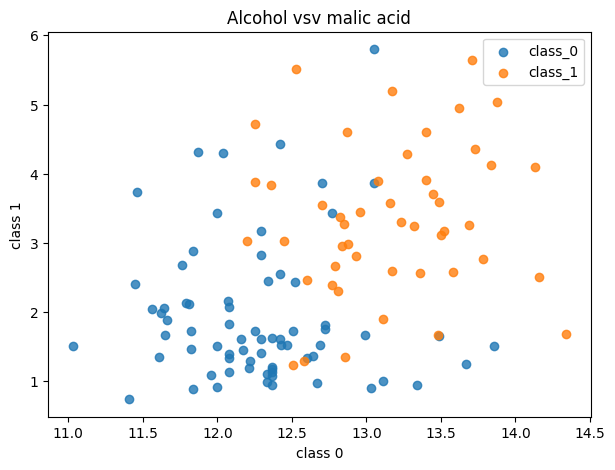

In [2]:
mask = (y == 1) | (y == 2)
X2 = X.loc[mask, ["alcohol", "malic_acid"]].to_numpy()
y2 = y[mask].to_numpy()

print("Number of samples per class:")
print(pd.Series(y2).value_counts())

plt.figure(figsize=(7, 5))
for cls, name, color in zip([1, 2], ["class_0", "class_1"], ["tab:blue", "tab:orange"]):
    pts = X2[y2 == cls]
    plt.scatter(pts[:, 0], pts[:, 1], label=name, alpha=0.8, c=color)
plt.xlabel("class 0")
plt.ylabel("class 1")
plt.title("Alcohol vsv malic acid")
plt.legend()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X2, y2, test_size=0.3, random_state=2026, stratify=y2
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print("Mean (train):", X_train_s.mean(axis=0).round(3))
print("Std  (train):", X_train_s.std(axis=0).round(3))

Mean (train): [-0.  0.]
Std  (train): [1. 1.]


In [4]:
from sklearn.svm import SVC

svm_hard = SVC(kernel='linear', C=100.0)
svm_hard.fit(X_train_s, y_train)

print("Training accuracy:", svm_hard.score(X_train_s, y_train))
print("Test accuracy    :", svm_hard.score(X_test_s, y_test))
print("Support vectors:", svm_hard.n_support_)

svm_soft = SVC(kernel='linear', C=0.1)
svm_soft.fit(X_train_s, y_train)

print("Training accuracy:", svm_soft.score(X_train_s, y_train))
print("Test accuracy    :", svm_soft.score(X_test_s, y_test))
print("Support Vectors:", svm_soft.n_support_)

Training accuracy: 0.8795180722891566
Test accuracy    : 0.7222222222222222
Support vectors: [13 14]
Training accuracy: 0.8795180722891566
Test accuracy    : 0.7222222222222222
Support Vectors: [19 20]


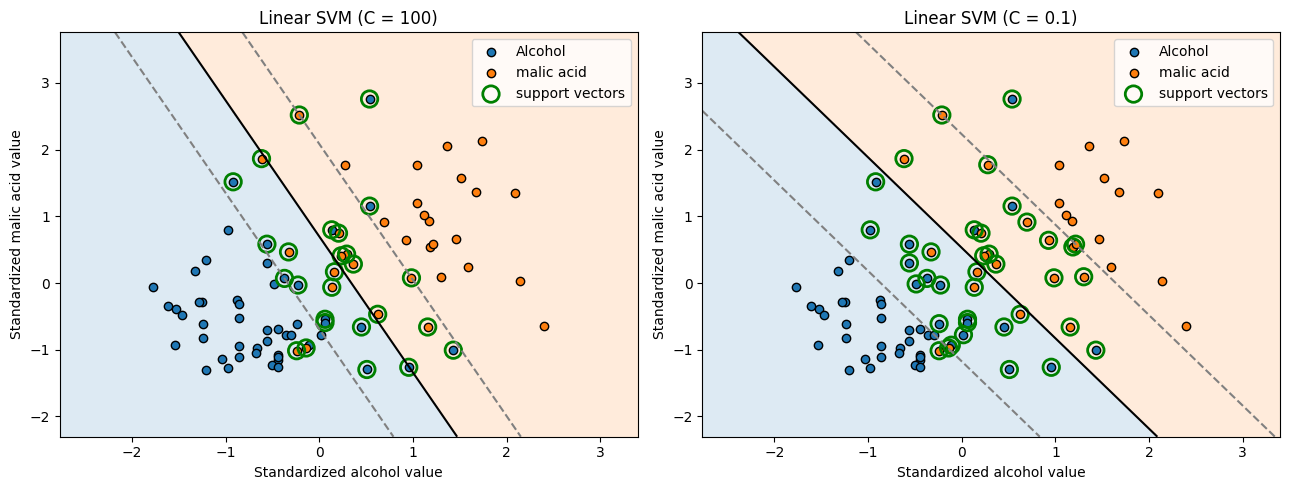

In [5]:
def plot_svm_boundary(model, X, y, ax, title):
    # Mesh grid in the standardized feature space
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Filled regions (predicted class)
    ax.contourf(xx, yy, np.sign(Z), levels=[-2, 0, 2], alpha=0.15, colors=['tab:blue', 'tab:orange'])

    # Decision boundary and margin boundaries
    ax.contour(xx, yy, Z, levels=[-1, 0, 1],
               colors=['gray', 'k', 'gray'], linestyles=['--', '-', '--'])

    for cls, name, color in zip([1, 2], ["Alcohol", "malic acid"], ["tab:blue", "tab:orange"]):
        pts = X[y == cls]
        ax.scatter(pts[:, 0], pts[:, 1], label=name, edgecolor='k', c=color)

    # Highlight support vectors
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=140, facecolors='none', edgecolors='green',
               linewidths=2, label='support vectors')
    ax.set_xlabel('Standardized alcohol value')
    ax.set_ylabel('Standardized malic acid value')
    ax.set_title(title)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_svm_boundary(svm_hard, X_train_s, y_train, axes[0], 'Linear SVM (C = 100)')
plot_svm_boundary(svm_soft, X_train_s, y_train, axes[1], 'Linear SVM (C = 0.1)')
plt.tight_layout()
plt.show()